<a href="https://colab.research.google.com/github/SamuelOUS/proyecto-3-procesamiento-lenguaje-natural/blob/main/Proyecto3_NLP_Emotion_FineTuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 3 – Procesamiento de Lenguaje Natural
## Fine-tuning de DistilBERT para clasificación de emociones en texto

**Autor:** Samuel Osorio Uribe  
**Curso:** Procesamiento de Lenguaje Natural  
**Dataset:** [`dair-ai/emotion`](https://huggingface.co/datasets/dair-ai/emotion) (Hugging Face)  
**Modelo base:** [`distilbert-base-uncased`](https://huggingface.co/distilbert-base-uncased)

> Ejecutar en Google Colab con GPU (Entorno de ejecución → Cambiar tipo → T4 GPU).

**Contenido**
1. Descripción de la base de datos
2. Análisis exploratorio
3. Preprocesamiento (tokenización)
4. Fine-tuning y experimentos de hiperparámetros
5. Mejor modelo y evaluación en test
6. Conclusiones

In [3]:
!pip install -q transformers datasets evaluate accelerate scikit-learn

In [4]:
import random, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, pipeline)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("GPU disponible:", torch.cuda.is_available())

GPU disponible: True


## 1. Descripción de la base de datos

- **Nombre:** `dair-ai/emotion` (Hugging Face Datasets).
- **Dominio del problema:** análisis de emociones en redes sociales. Son mensajes de Twitter en inglés etiquetados con la emoción principal que expresan.
- **Utilidad:** detectar el estado emocional de un texto sirve para monitoreo de reputación y escucha social, priorizar tickets de servicio al cliente según urgencia emocional, apoyo a sistemas de bienestar y chatbots empáticos.
- **Datos de entrada:** `text`, un mensaje corto en inglés.
- **Variable de salida:** `label`, una de 6 clases: `sadness`, `joy`, `love`, `anger`, `fear`, `surprise`.
- **Tipo de problema:** **clasificación de secuencias (sequence classification) multiclase**.
- **Tamaño:** 16.000 ejemplos de entrenamiento, 2.000 de validación y 2.000 de prueba.
- **Métricas:** *accuracy* y *F1 macro*. Se usa F1 macro porque las clases están desbalanceadas y esta métrica da el mismo peso a cada emoción.
- **Técnica:** fine-tuning de un modelo tipo BERT (DistilBERT) con una cabeza de clasificación sobre el token `[CLS]`.

In [5]:
dataset = load_dataset("dair-ai/emotion")
print(dataset)
label_names = dataset["train"].features["label"].names
id2label = {i: n for i, n in enumerate(label_names)}
label2id = {n: i for i, n in id2label.items()}
print(id2label)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
{0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}


## 2. Análisis exploratorio de datos

In [6]:
train_df = dataset["train"].to_pandas()
train_df["label_name"] = train_df["label"].map(id2label)
train_df["n_words"] = train_df["text"].str.split().str.len()
print("Nulos:", train_df.isnull().sum().to_dict())
print("Duplicados en texto:", train_df["text"].duplicated().sum())
train_df.head(10)

Nulos: {'text': 0, 'label': 0, 'label_name': 0, 'n_words': 0}
Duplicados en texto: 31


,text,label,label_name,n_words
0,i didnt feel humiliated,0,sadness,4
1,i can go from feeling so hopeless to so damned...,0,sadness,21
2,im grabbing a minute to post i feel greedy wrong,3,anger,10
3,i am ever feeling nostalgic about the fireplac...,2,love,18
4,i am feeling grouchy,3,anger,4
5,ive been feeling a little burdened lately wasn...,0,sadness,12
6,ive been taking or milligrams or times recomme...,5,surprise,23
7,i feel as confused about life as a teenager or...,4,fear,17
8,i have been with petronas for years i feel tha...,1,joy,19
9,i feel romantic too,2,love,4


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


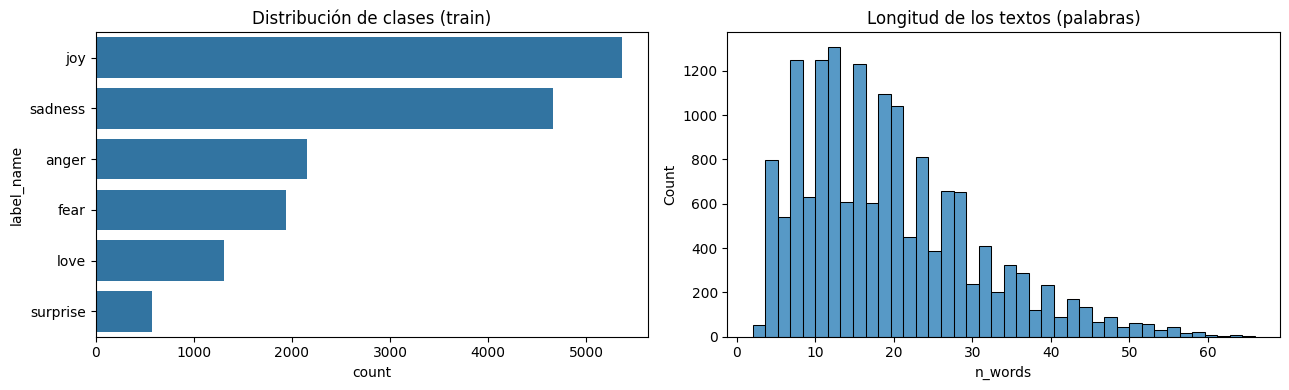

label_name
joy         0.335
sadness     0.292
anger       0.135
fear        0.121
love        0.082
surprise    0.036
Name: proportion, dtype: float64
count    16000.000000
mean        19.166313
std         10.986905
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: n_words, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = train_df["label_name"].value_counts().index
sns.countplot(data=train_df, y="label_name", order=order, ax=ax[0])
ax[0].set_title("Distribución de clases (train)")
sns.histplot(train_df["n_words"], bins=40, ax=ax[1])
ax[1].set_title("Longitud de los textos (palabras)")
plt.tight_layout(); plt.show()
print(train_df["label_name"].value_counts(normalize=True).round(3))
print(train_df["n_words"].describe())

In [8]:
# Ejemplos por clase para entender el problema
for name in label_names:
    print(f"\n=== {name.upper()} ===")
    for t in train_df[train_df.label_name == name]["text"].sample(3, random_state=SEED):
        print(" -", t)


=== SADNESS ===
 - im feeling so lousy they tried to cheer me up during school time and during choir practice
 - i feel highly disadvantaged
 - i feel humiliated to introduce you to my colleagues as my wife

=== JOY ===
 - i feel im rather innocent in that respect
 - im feeling quite adventurous and tried out those drinks that i just normally read through the pages of pocketbooks
 - im feeling much more positive about the impending move

=== LOVE ===
 - i mean fuck i feel like i was way more considerate with customers and concerned about appearance and sanitiation snoozel pm but fine
 - i remember a couple of years ago i was feeling romantic and dreamy and asked him wonder if we ll celebrate our th anniversary
 - im so going to end up feeling slutty and be like ah

=== ANGER ===
 - i ve been feeling a bit cranky with the kids this week cranky baby whiny year old demanding preschooler so i wanted to stop and remember how blessed i really am
 - i feel frustrated sometimes with my mac li

**Observaciones del EDA:** las clases están desbalanceadas (`joy` y `sadness` dominan; `love` y `surprise` son minoritarias). Los textos son cortos (en su mayoría menos de 30 palabras), por lo que `max_length=128` es más que suficiente. Por el desbalance, la métrica principal será **F1 macro**.

## 3. Preprocesamiento: tokenización

In [9]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

tokenized = dataset.map(tokenize, batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)  # padding dinámico por batch
tokenized

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
})

In [10]:
print(dataset["train"][0]["text"])
print(tokenizer.tokenize(dataset["train"][0]["text"]))

i didnt feel humiliated
['i', 'didn', '##t', 'feel', 'humiliated']


## 4. Fine-tuning y experimentos de hiperparámetros

Se define una función que entrena el modelo con una configuración dada y devuelve las métricas de validación. Se prueban distintos valores de **learning rate**, **batch size**, **épocas** y **weight decay**. Cada corrida usa la misma semilla para que la comparación sea justa. La selección del mejor modelo se hace con **validación**, y el conjunto de **test** se usa una sola vez al final.

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro")}

def run_experiment(run_id, lr, batch_size, epochs, weight_decay):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(label_names), id2label=id2label, label2id=label2id)
    args = TrainingArguments(
        output_dir=f"runs/run_{run_id}",
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        save_total_limit=1,
        fp16=torch.cuda.is_available(),
        seed=SEED,
        report_to="none",
        logging_strategy="epoch",
    )
    trainer = Trainer(model=model, args=args,
                      train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                      processing_class=tokenizer, data_collator=data_collator,
                      compute_metrics=compute_metrics)
    trainer.train()
    metrics = trainer.evaluate()
    trainer.save_model(f"runs/run_{run_id}/best")
    return {"run": run_id, "lr": lr, "batch_size": batch_size, "epochs": epochs,
            "weight_decay": weight_decay,
            "val_accuracy": metrics["eval_accuracy"], "val_f1_macro": metrics["eval_f1_macro"]}

In [12]:
configs = [
    # (lr,   batch, epochs, weight_decay)
    (1e-5, 32, 3, 0.01),
    (2e-5, 32, 3, 0.01),
    (5e-5, 32, 3, 0.01),
    (1e-4, 32, 3, 0.01),   # lr alto: ver si diverge o empeora
    (5e-5, 16, 3, 0.01),   # batch más pequeño
    (5e-5, 32, 5, 0.1),    # más épocas + más regularización
]
results = []
for i, (lr, bs, ep, wd) in enumerate(configs):
    print(f"\n########## Run {i}: lr={lr}, batch={bs}, epochs={ep}, wd={wd} ##########")
    results.append(run_experiment(i, lr, bs, ep, wd))

results_df = pd.DataFrame(results).sort_values("val_f1_macro", ascending=False).reset_index(drop=True)
results_df


########## Run 0: lr=1e-05, batch=32, epochs=3, wd=0.01 ##########


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.853553,0.318375,0.905500,0.847234
2,0.255059,0.199742,0.930000,0.904755
3,0.172351,0.187299,0.928000,0.900433


... (49 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.042038,0.125853,5,0.943500,0.918887


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,run,lr,batch_size,epochs,weight_decay,val_accuracy,val_f1_macro
0,4,0.00005,16,3,0.01,0.9460,0.923872
1,2,0.00005,32,3,0.01,0.9435,0.922049
2,3,0.00010,32,3,0.01,0.9455,0.920375
3,5,0.00005,32,5,0.10,0.9435,0.918887
4,1,0.00002,32,3,0.01,0.9350,0.909690
5,0,0.00001,32,3,0.01,0.9300,0.904755


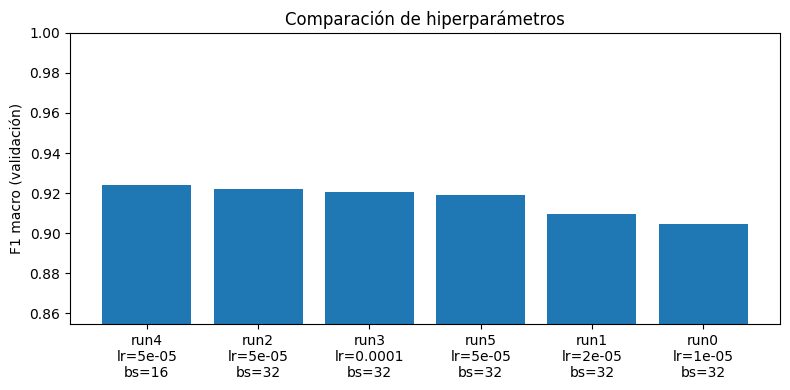

In [13]:
plt.figure(figsize=(8, 4))
labels = [f"run{r.run}\nlr={r.lr}\nbs={r.batch_size}" for r in results_df.itertuples()]
plt.bar(labels, results_df["val_f1_macro"])
plt.ylim(results_df["val_f1_macro"].min() - 0.05, 1.0)
plt.ylabel("F1 macro (validación)"); plt.title("Comparación de hiperparámetros")
plt.tight_layout(); plt.show()

## 5. Mejor modelo y evaluación final en test

In [14]:
best = results_df.iloc[0]
print("Mejor configuración:\n", best)
best_path = f"runs/run_{int(best.run)}/best"

best_model = AutoModelForSequenceClassification.from_pretrained(best_path)
final_trainer = Trainer(model=best_model, processing_class=tokenizer,
                        data_collator=data_collator, compute_metrics=compute_metrics,
                        args=TrainingArguments(output_dir="runs/final", per_device_eval_batch_size=64,
                                               report_to="none", fp16=torch.cuda.is_available()))
test_out = final_trainer.predict(tokenized["test"])
y_pred = np.argmax(test_out.predictions, axis=-1)
y_true = test_out.label_ids
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test F1 macro:", round(f1_score(y_true, y_pred, average="macro"), 4))
print(classification_report(y_true, y_pred, target_names=label_names))

Mejor configuración:
 run              4.000000
lr               0.000050
batch_size      16.000000
epochs           3.000000
weight_decay     0.010000
val_accuracy     0.946000
val_f1_macro     0.923872
Name: 0, dtype: float64


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Test accuracy: 0.9325
Test F1 macro: 0.8899
              precision    recall  f1-score   support

     sadness       0.97      0.97      0.97       581
         joy       0.94      0.96      0.95       695
        love       0.86      0.77      0.81       159
       anger       0.94      0.93      0.93       275
        fear       0.88      0.95      0.91       224
    surprise       0.87      0.68      0.76        66

    accuracy                           0.93      2000
   macro avg       0.91      0.88      0.89      2000
weighted avg       0.93      0.93      0.93      2000



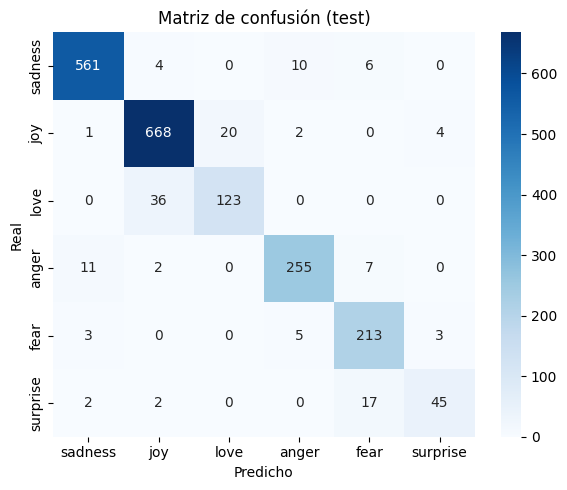

In [15]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_names, yticklabels=label_names)
plt.xlabel("Predicho"); plt.ylabel("Real"); plt.title("Matriz de confusión (test)")
plt.tight_layout(); plt.show()

In [16]:
# Inferencia con el mejor modelo
clf = pipeline("text-classification", model=best_model, tokenizer=tokenizer,
               device=0 if torch.cuda.is_available() else -1, top_k=None)
ejemplos = ["i am so happy that i passed my exam today",
            "i feel terrified walking alone at night",
            "i can't believe you did that, i am furious",
            "wow i did not expect this gift at all",
            "i miss my family and feel really down"]
for t in ejemplos:
    r = sorted(clf(t)[0], key=lambda x: -x["score"])[0]
    print(f"{t!r} -> {r['label']} ({r['score']:.2f})")

'i am so happy that i passed my exam today' -> joy (1.00)
'i feel terrified walking alone at night' -> fear (1.00)
"i can't believe you did that, i am furious" -> anger (1.00)
'wow i did not expect this gift at all' -> joy (0.63)
'i miss my family and feel really down' -> sadness (0.96)


In [17]:
# Errores del modelo: útil para el análisis
test_df = dataset["test"].to_pandas()
test_df["pred"] = [id2label[i] for i in y_pred]
test_df["real"] = test_df["label"].map(id2label)
test_df[test_df.pred != test_df.real][["text", "real", "pred"]].head(100)

,text,real,pred
10,i don t feel particularly agitated,fear,anger
40,i feel if i completely hated things i d exerci...,anger,sadness
67,i feel a bit stressed even though all the thin...,anger,sadness
72,i am right handed however i play billiards lef...,surprise,fear
86,i feel like i am in paradise kissing those swe...,joy,love
...,...,...,...
1282,im always feeling so agitated overly excited a...,anger,fear
1314,ive blogged and i feel strange about it,surprise,fear
1319,i still do feel left out i do feel like the mo...,anger,sadness
1328,i don t really know the oldest one very well a...,joy,love


## 6. Conclusiones

> **Completar con tus resultados reales después de ejecutar el notebook.**

- **Mejor modelo:** DistilBERT con lr = ___, batch = ___, épocas = ___, weight decay = ___ → F1 macro en validación = ___, y en test: accuracy = ___, F1 macro = ___.
- **Efecto del learning rate:** (¿qué pasó con 1e-5 vs 5e-5 vs 1e-4? ¿convergió lento, bien o se volvió inestable?).
- **Otros hiperparámetros:** (efecto del batch size, de más épocas y de más weight decay).
- **Análisis de errores:** (qué clases se confunden, por ejemplo `love` con `joy` o `surprise` con `fear`, y por qué: clases minoritarias y emociones semánticamente cercanas).
- **Mejoras posibles:** modelos más grandes (BERT/RoBERTa), balanceo de clases o pesos en la pérdida, aumento de datos, búsqueda automática de hiperparámetros (Optuna).